# 01 · Problema y exploración

En este notebook planteamos el problema de las cancelaciones de reservas, describimos el dataset *Hotel Booking Demand* y lo exploramos antes de preparar los datos para los modelos.

## 1. El problema y los datos

### 1.1 Por qué le cuestan tanto las cancelaciones a un hotel

Una noche de hotel es un producto que se vence: si la habitación queda vacía hoy, esa noche ya no se puede vender después. Por eso las cancelaciones le salen caras a un hotel. Mientras la reserva está activa, la habitación queda bloqueada y se deja de ofrecer a otros clientes, y si el cliente cancela a última hora o simplemente no llega (*no-show*), muchas veces ya no hay tiempo de volverla a vender. Esa plata se pierde.

Los hoteles se defienden de dos formas, y las dos tienen su costo:

- **Sobreventa (*overbooking*).** Venden más habitaciones de las que tienen, contando con que algunos clientes van a cancelar. Si se equivocan y llegan todos, toca reubicar huéspedes en otro hotel, pagar ese traslado y quedar mal con el cliente.
- **Políticas más estrictas.** Piden depósitos que no se devuelven o cobran por cancelar. Eso baja las cancelaciones, pero también puede espantar a clientes que sí iban a llegar.

Las dos funcionan mejor si el hotel sabe, en el momento en que entra una reserva, qué tan probable es que se cancele. Ahí entra este trabajo: nos ponemos en el lugar del área comercial de un hotel que quiere anticipar las cancelaciones y entender qué tipos de reservas recibe, para tratarlas distinto en vez de aplicarles a todas la misma política.

Un modelo que anticipe cancelaciones se puede equivocar de dos maneras. Si dice que una reserva no se va a cancelar y sí se cancela, el hotel no se prepara y la habitación puede quedar vacía. Si dice que se va a cancelar y el cliente sí llega, el hotel puede sobrevender esa habitación y terminar reubicando a alguien. Ninguno de los dos errores es gratis, y por eso en el componente supervisado miramos el Recall (de las cancelaciones reales, cuántas detecta el modelo), la Precision (de las reservas que marca como canceladas, cuántas lo eran), el F1, que combina las dos, y el ROC-AUC, que mide qué tan bien ordena el modelo las reservas de más a menos riesgo sin depender de un umbral.

### 1.2 Objetivo

Anticipar, con la información que se tiene en el momento de hacer la reserva, si una reserva se va a cancelar, y encontrar grupos de reservas con un comportamiento parecido, para proponerle al hotel estrategias que reduzcan las cancelaciones o lo que le cuestan.

Para eso nos propusimos:

1. Entender qué variables se relacionan con la cancelación y cuáles no se pueden usar porque solo se conocen después de reservar.
2. Entrenar y comparar dos modelos supervisados, una regresión logística y un bosque aleatorio, con F1, Recall, Precision y ROC-AUC.
3. Agrupar las reservas con dos métodos, K-Means y agrupamiento jerárquico, sin usar `is_canceled`, y describir qué tiene cada grupo.
4. Comparar lo que aporta cada enfoque y convertir los resultados en recomendaciones para el hotel.

### 1.3 Preguntas que vamos a responder

1. ¿Qué características de una reserva permiten anticipar que se va a cancelar?
2. ¿Qué tan bien se puede predecir una cancelación solo con lo que se sabe al momento de reservar?
3. ¿Qué perfiles de reservas existen?
4. ¿Cómo se relacionan esos perfiles con las cancelaciones y qué estrategias sugieren?

Las dos primeras las responde el componente supervisado (notebook 03), la tercera el no supervisado (notebook 04) y la cuarta junta los dos. Las ocho preguntas de comparación que pide el enunciado las respondemos en el notebook 05.

### 1.4 El dataset

Trabajamos con **Hotel Booking Demand**, publicado en Kaggle por Jesse Mostipak ([enlace](https://www.kaggle.com/datasets/jessemostipak/hotel-booking-demand)). Los datos vienen del artículo de Nuno Antonio, Ana de Almeida y Luis Nunes, *Hotel booking demand datasets* (*Data in Brief*, vol. 22, 2019, [doi](https://doi.org/10.1016/j.dib.2018.11.083)). Ellos los sacaron del sistema de gestión de reservas de dos hoteles de Portugal: un hotel de playa en el Algarve (*Resort Hotel*) y un hotel de ciudad en Lisboa (*City Hotel*). Cada fila es una reserva con llegada prevista entre julio de 2015 y agosto de 2017, haya llegado el cliente o no.

**Tipo de fuente: secundaria.** Los datos no los recogimos nosotros: salieron del sistema de los hoteles y los autores los anonimizaron antes de publicarlos. Por eso los hoteles no tienen nombre y la agencia, la empresa y los tipos de habitación vienen como códigos. Y por lo mismo no sabemos con detalle en qué momento se llenó cada campo. Por ejemplo, no sabemos si el país del cliente se registra al reservar o se corrige cuando llega al hotel, y eso importa para decidir si lo podemos usar en el modelo.

También hay que tener presente desde ya que son solo dos hoteles de un mismo país y de antes de la pandemia. Lo que encontremos describe a esos dos hoteles en esos años y no se puede pasar sin más a otros hoteles.

El archivo lo dejamos en `data/raw/hotel_bookings.csv.zip`, comprimido tal como se descarga de Kaggle.

### 1.5 Diccionario de variables

Las 32 columnas, agrupadas por tema. Las descripciones las sacamos del artículo original.

| Tema | Variable | Qué es |
|---|---|---|
| Resultado | `is_canceled` | **Variable objetivo.** 1 si la reserva se canceló y 0 si no |
| | `reservation_status` | Último estado de la reserva: *Canceled* (cancelada), *Check-Out* (el cliente llegó y ya se fue) o *No-Show* (el cliente no llegó) |
| | `reservation_status_date` | Fecha en que se registró ese último estado |
| Reserva | `hotel` | *Resort Hotel* (Algarve) o *City Hotel* (Lisboa) |
| | `lead_time` | Días entre el día en que se hizo la reserva y la fecha de llegada |
| | `deposit_type` | Depósito que se pidió: *No Deposit* (ninguno), *Non Refund* (por el valor total de la estadía, sin devolución) o *Refundable* (por menos del valor total) |
| | `days_in_waiting_list` | Días que la reserva estuvo en lista de espera antes de que se le confirmara al cliente |
| | `adr` | Tarifa diaria promedio (*Average Daily Rate*): lo que se cobra por alojamiento dividido entre el número de noches |
| | `meal` | Plan de comidas: *BB* (desayuno), *HB* (desayuno y otra comida), *FB* (las tres comidas), *SC* o *Undefined* (sin plan) |
| | `required_car_parking_spaces` | Parqueaderos que pidió el cliente |
| | `total_of_special_requests` | Pedidos especiales del cliente, como cama doble o un piso alto |
| Llegada y estadía | `arrival_date_year`, `arrival_date_month`, `arrival_date_week_number`, `arrival_date_day_of_month` | Año, mes, semana del año y día del mes de la llegada |
| | `stays_in_weekend_nights` | Noches de sábado o domingo que incluye la reserva |
| | `stays_in_week_nights` | Noches de lunes a viernes que incluye la reserva |
| Huéspedes | `adults`, `children`, `babies` | Número de adultos, niños y bebés |
| | `country` | País de origen del cliente, como código (por ejemplo `PRT` es Portugal y `GBR` el Reino Unido) |
| | `is_repeated_guest` | 1 si el cliente ya se había hospedado en el hotel |
| | `previous_cancellations` | Reservas anteriores que el cliente canceló |
| | `previous_bookings_not_canceled` | Reservas anteriores que el cliente no canceló |
| | `customer_type` | *Transient* (reserva suelta), *Transient-Party* (suelta, pero ligada a otra reserva), *Group* (de un grupo) o *Contract* (con un contrato o un cupo asignado) |
| Canal | `market_segment` | Segmento de mercado, por ejemplo *Online TA* (agencias en línea), *Offline TA/TO* (agencias y operadores turísticos tradicionales), *Direct*, *Groups* o *Corporate* |
| | `distribution_channel` | Canal por el que llegó la reserva (*TA/TO*, *Direct*, *Corporate*, *GDS* o *Undefined*) |
| | `agent` | Código de la agencia de viajes que hizo la reserva |
| | `company` | Código de la empresa que hizo la reserva o la paga |
| Habitación | `reserved_room_type` | Tipo de habitación reservada (código anonimizado) |
| | `assigned_room_type` | Tipo de habitación que se le asignó al final. Puede ser distinta de la reservada, por sobreventa o porque el cliente lo pidió |
| | `booking_changes` | Cambios que se le hicieron a la reserva desde que se registró hasta el check-in o la cancelación |

El primer grupo hay que leerlo con cuidado. `reservation_status` dice qué pasó con la reserva, o sea que repite la respuesta que queremos predecir, y su fecha es la del día en que se canceló o terminó la estadía. Como el modelo se usaría cuando entra una reserva, la regla que acordamos es que una variable solo entra si se conoce en ese momento. Con esa regla también quedan en duda columnas como `assigned_room_type` y `booking_changes`, que pueden cambiar hasta el día de la llegada. Eso lo revisamos con datos en la sección 3, y el notebook 02 deja por fuera las que no cumplan.

### 1.6 Carga de los datos

Leemos el CSV directamente desde el `.zip` (pandas lo descomprime al leerlo). Arriba dejamos las constantes que usamos en todo el notebook: la semilla, la ruta de los datos, la variable objetivo y los colores de las gráficas.

In [1]:
from pathlib import Path

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

SEMILLA = 42
RUTA_DATOS = Path("../data/raw/hotel_bookings.csv.zip")
OBJETIVO = "is_canceled"

MESES = ["January", "February", "March", "April", "May", "June", "July",
         "August", "September", "October", "November", "December"]

COLOR_PRINCIPAL = "#087F8C"
COLOR_SECUNDARIO = "#A0AEC0"
COLOR_RIESGO = "#916313"
COLORES_HOTEL = {"City Hotel": COLOR_PRINCIPAL, "Resort Hotel": COLOR_SECUNDARIO}

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 40)

In [2]:
reservas = pd.read_csv(RUTA_DATOS)

canceladas = reservas[OBJETIVO].sum()
print(f"{len(reservas):,} reservas y {reservas.shape[1]} columnas")
print(f"Canceladas: {canceladas:,} ({canceladas / len(reservas):.1%})")

119,390 reservas y 32 columnas
Canceladas: 44,224 (37.0%)


In [3]:
reservas.head()

,hotel,is_canceled,lead_time,arrival_date_year,arrival_date_month,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,children,babies,meal,country,market_segment,distribution_channel,is_repeated_guest,previous_cancellations,previous_bookings_not_canceled,reserved_room_type,assigned_room_type,booking_changes,deposit_type,agent,company,days_in_waiting_list,customer_type,adr,required_car_parking_spaces,total_of_special_requests,reservation_status,reservation_status_date
0,Resort Hotel,0,342,2015,July,27,1,0,0,2,0.0,0,BB,PRT,Direct,Direct,0,0,0,C,C,3,No Deposit,NaN,NaN,0,Transient,0.0,0,0,Check-Out,2015-07-01
1,Resort Hotel,0,737,2015,July,27,1,0,0,2,0.0,0,BB,PRT,Direct,Direct,0,0,0,C,C,4,No Deposit,NaN,NaN,0,Transient,0.0,0,0,Check-Out,2015-07-01
2,Resort Hotel,0,7,2015,July,27,1,0,1,1,0.0,0,BB,GBR,Direct,Direct,0,0,0,A,C,0,No Deposit,NaN,NaN,0,Transient,75.0,0,0,Check-Out,2015-07-02
3,Resort Hotel,0,13,2015,July,27,1,0,1,1,0.0,0,BB,GBR,Corporate,Corporate,0,0,0,A,A,0,No Deposit,304.0,NaN,0,Transient,75.0,0,0,Check-Out,2015-07-02
4,Resort Hotel,0,14,2015,July,27,1,0,2,2,0.0,0,BB,GBR,Online TA,TA/TO,0,0,0,A,A,0,No Deposit,240.0,NaN,0,Transient,98.0,0,1,Check-Out,2015-07-03


Cada fila es una reserva y las columnas son las del diccionario. La fecha de llegada viene partida en cuatro columnas (año, mes escrito en inglés, número de semana y día del mes), así que para ver qué periodo cubren los datos toca unirla.

### 1.7 Qué periodo cubren los datos

Unimos año, mes y día en una sola fecha de llegada y contamos las reservas por hotel y por año. Aquí cuentan todas las reservas, canceladas o no.

In [4]:
def fecha_de_llegada(datos):
    """Une las columnas de año, mes y día en una sola fecha de llegada."""
    numero_de_mes = {mes: numero for numero, mes in enumerate(MESES, start=1)}
    partes = pd.DataFrame({
        "year": datos["arrival_date_year"],
        "month": datos["arrival_date_month"].map(numero_de_mes),
        "day": datos["arrival_date_day_of_month"],
    })
    return pd.to_datetime(partes)


llegada = fecha_de_llegada(reservas)

resumen_hoteles = (
    reservas.assign(llegada=llegada)
    .groupby("hotel")
    .agg(reservas=("hotel", "size"),
         primera_llegada=("llegada", "min"),
         ultima_llegada=("llegada", "max"))
)
resumen_hoteles["porcentaje"] = (resumen_hoteles["reservas"] / len(reservas) * 100).round(1)
resumen_hoteles

,reservas,primera_llegada,ultima_llegada,porcentaje
hotel,,,,
City Hotel,79330,2015-07-01,2017-08-31,66.4
Resort Hotel,40060,2015-07-01,2017-08-31,33.6


In [5]:
reservas_por_anio = llegada.groupby(llegada.dt.year).agg(
    reservas="size",
    meses_con_datos=lambda fechas: fechas.dt.month.nunique(),
)
reservas_por_anio.index.name = "año"
reservas_por_anio

,reservas,meses_con_datos
año,,
2015,21996,6
2016,56707,12
2017,40687,8


**¿Qué vemos?**

- Los dos hoteles tienen llegadas en todo el periodo, del 1 de julio de 2015 al 31 de agosto de 2017. El City Hotel tiene dos de cada tres reservas (79.330, el 66,4 %) y el Resort Hotel el resto (40.060).
- Solo 2016 está completo. De 2015 hay 6 meses (julio a diciembre) y de 2017 hay 8 (enero a agosto). Por eso los totales por año no se pueden comparar: que 2016 tenga 56.707 reservas y 2015 solo 21.996 no quiere decir que la demanda se haya disparado, sino que a 2015 le faltan seis meses.

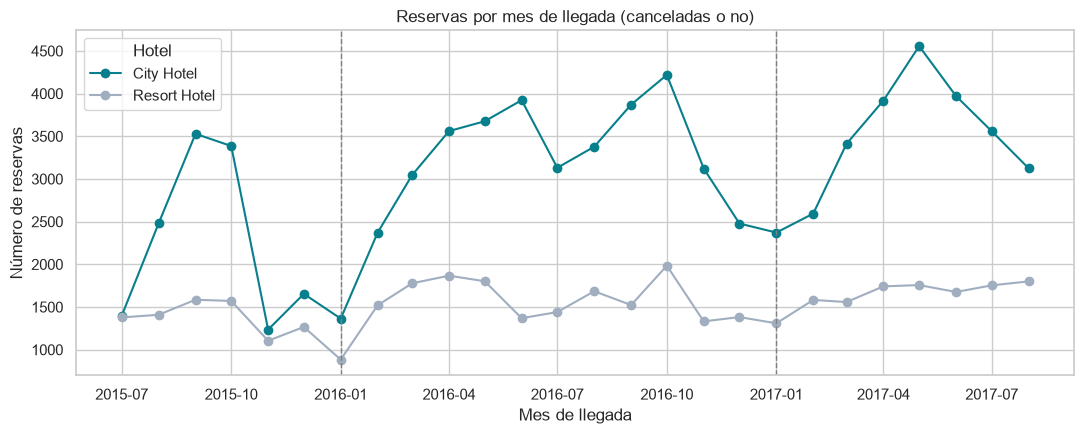

City Hotel: el mes con menos reservas es 2015-11 (1,235) y el de más es 2017-05 (4,556)
Resort Hotel: el mes con menos reservas es 2016-01 (884) y el de más es 2016-10 (1,984)


In [6]:
reservas_por_mes = (
    reservas.assign(mes=llegada.dt.to_period("M").dt.to_timestamp())
    .groupby(["hotel", "mes"])
    .size()
    .rename("reservas")
    .reset_index()
)

fig, ax = plt.subplots(figsize=(11, 4.5))
for hotel, datos in reservas_por_mes.groupby("hotel"):
    ax.plot(datos["mes"], datos["reservas"], marker="o", color=COLORES_HOTEL[hotel], label=hotel)
for anio in (2016, 2017):
    ax.axvline(pd.Timestamp(anio, 1, 1), color="gray", linestyle="--", linewidth=1)
ax.set_title("Reservas por mes de llegada (canceladas o no)")
ax.set_xlabel("Mes de llegada")
ax.set_ylabel("Número de reservas")
ax.legend(title="Hotel")
plt.tight_layout()
plt.show()

for hotel, datos in reservas_por_mes.groupby("hotel"):
    menor = datos.loc[datos["reservas"].idxmin()]
    mayor = datos.loc[datos["reservas"].idxmax()]
    print(f"{hotel}: el mes con menos reservas es {menor['mes']:%Y-%m} ({menor['reservas']:,}) "
          f"y el de más es {mayor['mes']:%Y-%m} ({mayor['reservas']:,})")

**¿Qué vemos?**

- El City Hotel no solo tiene más reservas, también cambia mucho más de un mes a otro: va de 1.235 reservas en noviembre de 2015 a 4.556 en mayo de 2017. Baja hacia diciembre y enero, y tiene sus picos en primavera (abril a junio) y en septiembre-octubre. El Resort Hotel se mueve en un rango más corto, entre 884 reservas (enero de 2016) y 1.984 (octubre de 2016).
- En julio y agosto de 2015 el City Hotel tiene bastantes menos reservas que en los mismos meses de 2016 y 2017. Con estos datos no sabemos si es que tenía menos demanda o si el registro arrancó incompleto, así que tampoco sacamos conclusiones de tendencia entre años.
- Como la demanda sube y baja tanto según el mes, es posible que el mes de llegada también pese en las cancelaciones. Eso no lo podemos concluir de esta gráfica, que cuenta todas las reservas juntas; lo miramos en la sección 3.

### 1.8 Cierre de la sección

- El problema es grande para estos dos hoteles: de 119.390 reservas se cancelaron 44.224, el 37,0 %.
- Los datos cubren 26 meses, pero solo 2016 está completo, y son de solo dos hoteles de Portugal. Lo que encontremos vale para ellos y no se puede generalizar sin más.
- Para predecir solo podemos usar lo que se sabe al momento de reservar, y el dataset trae columnas que se llenan después.

Antes de mirar las cancelaciones hay que revisar qué tan limpios vienen los datos, y eso es lo que hacemos en la sección 2.

## 2. Calidad de los datos

Antes de mirar las cancelaciones revisamos qué tan confiables vienen los datos. En esta sección solo hacemos el **diagnóstico**: no borramos ni cambiamos nada de `reservas`. Lo que proponemos al final lo aplica el notebook 02, dentro del preprocesamiento, para que todo lo que se ajuste con datos se aprenda solo con entrenamiento.

Revisamos, en este orden:

1. Valores faltantes y qué significa cada uno.
2. Tipos de datos y conversiones necesarias.
3. Filas duplicadas.
4. Valores imposibles o muy raros.
5. Atípicos de `lead_time`, `adr` y noches.
6. Variables categóricas de alta cardinalidad (`country`, `agent` y `company`).

Arriba dejamos las constantes de la sección. El total de noches y de huéspedes lo calculamos aparte, solo para el diagnóstico, sin agregarlo a `reservas`.

In [7]:
FACTOR_IQR = 1.5
TARIFA_MAXIMA_RAZONABLE = 1_000
TOPES_CATEGORIAS = (5, 10, 20)
MINIMO_RESERVAS_CATEGORIA = 100
COLUMNAS_ALTA_CARDINALIDAD = ["country", "agent", "company"]
COLUMNAS_CON_UNDEFINED = ["meal", "market_segment", "distribution_channel"]

total_noches = reservas["stays_in_weekend_nights"] + reservas["stays_in_week_nights"]
total_huespedes = reservas["adults"] + reservas["children"].fillna(0) + reservas["babies"]

### 2.1 Valores faltantes

Para cada columna con faltantes contamos cuántos hay y comparamos el porcentaje de cancelación de las reservas con el dato vacío contra las que sí lo tienen. Si las dos tasas son muy distintas, el faltante no es al azar: dice algo de la reserva.

In [8]:
def resumen_faltantes(datos):
    """Cantidad y porcentaje de faltantes por columna, y la cancelación con y sin el dato."""
    faltantes = datos.isna().sum()
    faltantes = faltantes[faltantes > 0].sort_values(ascending=False)
    filas = []
    for columna, cantidad in faltantes.items():
        vacio = datos[columna].isna()
        filas.append({
            "columna": columna,
            "faltantes": cantidad,
            "porcentaje": round(cantidad / len(datos) * 100, 2),
            "cancelacion_con_faltante_%": round(datos.loc[vacio, OBJETIVO].mean() * 100, 1),
            "cancelacion_con_dato_%": round(datos.loc[~vacio, OBJETIVO].mean() * 100, 1),
        })
    return pd.DataFrame(filas).set_index("columna")


resumen_faltantes(reservas)

,faltantes,porcentaje,cancelacion_con_faltante_%,cancelacion_con_dato_%
columna,,,,
company,112593,94.31,38.2,17.5
agent,16340,13.69,24.7,39.0
country,488,0.41,13.7,37.1
children,4,0.00,100.0,37.0


Para entender de dónde salen los faltantes de `agent` los cruzamos con el canal de distribución, y miramos en qué hotel quedaron las reservas sin país.

In [9]:
sin_agente = reservas["agent"].isna().map({True: "sin agente", False: "con agente"})
display(pd.crosstab(reservas["distribution_channel"], sin_agente, margins=True, margins_name="total"))

print("Reservas sin país, por hotel:")
print(reservas.loc[reservas["country"].isna(), "hotel"].value_counts().to_string())

agent,con agente,sin agente,total
distribution_channel,,,
Corporate,1134,5543,6677
Direct,7020,7625,14645
GDS,191,2,193
TA/TO,94703,3167,97870
Undefined,2,3,5
total,103050,16340,119390


Reservas sin país, por hotel:
hotel
Resort Hotel    464
City Hotel       24


Además de los vacíos, hay columnas de texto que traen el valor `Undefined`, que en la práctica también es un dato que no se registró.

In [10]:
for columna in COLUMNAS_CON_UNDEFINED:
    cantidad = (reservas[columna] == "Undefined").sum()
    print(f"{columna}: {cantidad:,} reservas con 'Undefined'")

meal: 1,169 reservas con 'Undefined'
market_segment: 2 reservas con 'Undefined'
distribution_channel: 5 reservas con 'Undefined'


**¿Qué vemos?**

- Solo cuatro columnas tienen vacíos y en ninguna parece un error de captura. Son faltantes **estructurales**: el campo queda vacío porque no aplica.
- `company` está vacía en 112.593 reservas (94,31 %). Lo normal es que la reserva no la haga ni la pague una empresa, así que el vacío quiere decir "no es de empresa". Las reservas con empresa cancelan mucho menos (17,5 % contra 38,2 %), y por eso no conviene borrar la columna sin más: lo que aporta es saber si hay empresa o no.
- `agent` falta en 16.340 reservas (13,69 %). Casi todas las reservas que llegan por agencias (*TA/TO*) tienen agente (94.703 de 97.870), mientras que en los canales *Direct* y *Corporate* la mayoría no lo tiene (7.625 de 14.645 y 5.543 de 6.677). O sea, el vacío casi siempre significa que la reserva se hizo sin agencia. Esas reservas cancelan menos (24,7 % contra 39,0 %).
- `country` falta en 488 reservas (0,41 %), casi todas del Resort Hotel (464). Cancelan 13,7 %, bastante menos que el 37,1 % de las que tienen país. Esto refuerza la duda que dejamos planteada en la sección 1.4: el país se puede estar llenando o corrigiendo cuando el cliente llega. Si es así, una reserva que nunca llegó tiene más probabilidad de quedarse sin país, y la variable estaría filtrando parte de la respuesta. Eso lo revisa con evidencia la sección 3.
- `children` solo falta en 4 reservas, todas del City Hotel en 2015 y todas canceladas. Son tan pocas que ponerles 0 no cambia nada.
- Los `Undefined` son pocos: 2 en `market_segment` y 5 en `distribution_channel`. En `meal` son 1.169; según el artículo original, `Undefined` y `SC` quieren decir lo mismo (sin plan de comidas), así que se pueden unir.

Lo que no permite concluir esta tabla: que las reservas sin agente o con empresa cancelen menos no quiere decir que el agente cause cancelaciones; puede ser el canal o el tipo de cliente que va detrás. Eso es asociación, no causa.

### 2.2 Tipos de datos

Miramos el tipo con el que pandas leyó cada columna, cuántos valores distintos tiene y un ejemplo de la primera fila.

In [11]:
tipos = pd.DataFrame({
    "tipo": reservas.dtypes.astype(str),
    "valores_distintos": reservas.nunique(),
    "ejemplo": reservas.iloc[0],
})
tipos

,tipo,valores_distintos,ejemplo
hotel,str,2,Resort Hotel
is_canceled,int64,2,0
lead_time,int64,479,342
arrival_date_year,int64,3,2015
arrival_date_month,str,12,July
arrival_date_week_number,int64,53,27
arrival_date_day_of_month,int64,31,1
stays_in_weekend_nights,int64,17,0
stays_in_week_nights,int64,35,0
adults,int64,14,2


In [12]:
print("Columnas decimales:", reservas.select_dtypes("float").columns.tolist())
print("Columnas de texto:", reservas.select_dtypes(exclude="number").columns.tolist())

Columnas decimales: ['children', 'agent', 'company', 'adr']
Columnas de texto: ['hotel', 'arrival_date_month', 'meal', 'country', 'market_segment', 'distribution_channel', 'reserved_room_type', 'assigned_room_type', 'deposit_type', 'customer_type', 'reservation_status', 'reservation_status_date']


**¿Qué vemos?**

Los tipos casi todos están bien, pero hay cuatro casos que toca resolver en el preprocesamiento:

- `children` quedó como decimal solo porque tiene 4 vacíos (pandas no guarda vacíos en columnas enteras). Después de ponerles 0 se puede volver entero.
- `agent` y `company` se leyeron como números decimales, pero son **códigos**: la agencia 240 no es "más" que la agencia 9. Si entran como números, un modelo lineal les daría un orden que no existe. Hay que tratarlas como categorías.
- `arrival_date_month` viene como texto en inglés. Para usarla como número o para ordenar por fecha hay que pasarla a número de mes, como ya hizo la función `fecha_de_llegada` de la sección 1.
- `reservation_status_date` es una fecha guardada como texto. No vale la pena convertirla porque no puede entrar al modelo: es la fecha del último estado, o sea, se conoce después.

Las variables `is_canceled` e `is_repeated_guest` son binarias (0 y 1) y ya vienen como enteros, que es lo que necesitamos.

### 2.3 Filas duplicadas

El dataset no trae un número de reserva, así que no hay forma de saber si dos filas idénticas son la misma reserva copiada dos veces o dos reservas distintas que coinciden en todo. Contamos cuántas hay y miramos cómo son.

In [13]:
duplicadas = reservas.duplicated()
con_alguna_copia = reservas.duplicated(keep=False)
veces_repetida = reservas.groupby(list(reservas.columns), dropna=False).size()
veces_repetida = veces_repetida[veces_repetida > 1]

print(f"Filas idénticas a otra que aparece antes: {duplicadas.sum():,} ({duplicadas.mean():.1%})")
print(f"Filas que tienen al menos una copia: {con_alguna_copia.sum():,} ({con_alguna_copia.mean():.1%})")
print(f"Combinaciones que se repiten: {len(veces_repetida):,}. "
      f"La mitad se repite {veces_repetida.median():.0f} veces y la que más, {veces_repetida.max()} veces")
print(f"Cancelación en las filas repetidas: {reservas.loc[duplicadas, OBJETIVO].mean():.1%}")
print(f"Cancelación si dejamos una sola fila por combinación: {reservas.loc[~duplicadas, OBJETIVO].mean():.1%}")

Filas idénticas a otra que aparece antes: 31,994 (26.8%)
Filas que tienen al menos una copia: 40,165 (33.6%)
Combinaciones que se repiten: 8,171. La mitad se repite 2 veces y la que más, 180 veces
Cancelación en las filas repetidas: 63.1%
Cancelación si dejamos una sola fila por combinación: 27.5%


In [14]:
def comparar_composicion(datos, mascara, columna, nombre):
    """Porcentaje de cada categoría dentro de las filas marcadas y en todo el dataset."""
    return pd.DataFrame({
        f"{nombre}_%": datos.loc[mascara, columna].value_counts(normalize=True).mul(100).round(1),
        "todas_%": datos[columna].value_counts(normalize=True).mul(100).round(1),
    }).fillna(0).sort_values(f"{nombre}_%", ascending=False)


display(comparar_composicion(reservas, duplicadas, "market_segment", "repetidas"))
display(comparar_composicion(reservas, duplicadas, "deposit_type", "repetidas"))

sin_reembolso = reservas["deposit_type"] == "Non Refund"
print(f"De las {sin_reembolso.sum():,} reservas 'Non Refund', el {duplicadas[sin_reembolso].mean():.1%} está repetida")

,repetidas_%,todas_%
market_segment,,
Groups,46.5,16.6
Offline TA/TO,32.3,20.3
Online TA,15.2,47.3
Corporate,3.4,4.4
Direct,2.5,10.6
Complementary,0.1,0.6
Aviation,0.0,0.2
Undefined,0.0,0.0


,repetidas_%,todas_%
deposit_type,,
No Deposit,57.5,87.6
Non Refund,42.3,12.2
Refundable,0.2,0.1


De las 14,587 reservas 'Non Refund', el 92.9% está repetida


**¿Qué vemos?**

- Hay 31.994 filas idénticas a otra (26,8 %), y si contamos también la primera aparición de cada una, 40.165 filas (33,6 %) tienen por lo menos una copia. La mayoría de las combinaciones se repiten 2 veces, pero hay una que aparece 180 veces.
- Las repetidas no se parecen al resto. El 46,5 % son del segmento *Groups*, que en todo el dataset es solo el 16,6 %, y el 42,3 % son *Non Refund*, contra 12,2 % en general. Eso cuadra con reservas de grupo: una agencia bloquea varias habitaciones iguales el mismo día, con la misma tarifa y las mismas fechas, y en el sistema quedan como filas idénticas. O sea, muchas de las "copias" pueden ser habitaciones reales distintas.
- Pesan mucho en la variable objetivo: las repetidas cancelan 63,1 %. Si dejamos una sola fila por combinación, la cancelación baja de 37,0 % a 27,5 %. Además, el 92,9 % de las reservas *Non Refund* está repetida; esto hay que tenerlo en cuenta en la sección 3 cuando se mire por qué ese tipo de depósito cancela tanto.

**Por qué son un problema al partir los datos.** Si partimos en entrenamiento y prueba al azar con las copias adentro, es casi seguro que una fila queda en entrenamiento y su gemela en prueba. El modelo "se aprende" esa fila y en prueba la acierta sin haber generalizado nada, así que las métricas salen mejores de lo que el modelo realmente es. Es una forma de fuga de información.

**Lo que no podemos saber.** Sin un número de reserva no hay manera de separar las copias por error de las habitaciones reales de un grupo. Cualquier decisión tiene un costo: si las quitamos, perdemos reservas reales y cambiamos la tasa de cancelación; si las dejamos, inflamos las métricas. Nuestra propuesta para el notebook 02 está en la tabla del cierre.

### 2.4 Valores imposibles o muy raros

Definimos reglas para lo que no puede pasar en una reserva real (una tarifa negativa, una reserva sin huéspedes) y para lo que es posible pero muy raro, y contamos cuántas filas cumplen cada una.

In [15]:
reglas = {
    "Tarifa (adr) negativa": ("imposible", reservas["adr"] < 0),
    f"Tarifa (adr) mayor a {TARIFA_MAXIMA_RAZONABLE:,}": ("imposible", reservas["adr"] > TARIFA_MAXIMA_RAZONABLE),
    "Cero huéspedes": ("imposible", total_huespedes == 0),
    "Cero noches": ("raro", total_noches == 0),
    "Niños o bebés sin ningún adulto": ("raro", (reservas["adults"] == 0) & (total_huespedes > 0)),
    "Nueve o más niños o bebés": ("raro", (reservas["children"] >= 9) | (reservas["babies"] >= 9)),
}

valores_raros = pd.DataFrame([
    {
        "regla": regla,
        "tipo": tipo,
        "reservas": mascara.sum(),
        "canceladas_%": round(reservas.loc[mascara, OBJETIVO].mean() * 100, 1),
        "tarifa_mediana": reservas.loc[mascara, "adr"].median(),
    }
    for regla, (tipo, mascara) in reglas.items()
]).set_index("regla")
valores_raros

,tipo,reservas,canceladas_%,tarifa_mediana
regla,,,,
Tarifa (adr) negativa,imposible,1,0.0,-6.38
"Tarifa (adr) mayor a 1,000",imposible,1,100.0,5400.00
Cero huéspedes,imposible,180,13.9,0.00
Cero noches,raro,715,4.9,0.00
Niños o bebés sin ningún adulto,raro,223,37.7,88.77
Nueve o más niños o bebés,raro,3,33.3,95.00


Miramos las filas de las dos tarifas imposibles y qué tarifas siguen después de la más alta.

In [16]:
columnas_detalle = ["hotel", "adr", "adults", "children", "stays_in_weekend_nights",
                    "stays_in_week_nights", "market_segment", "is_canceled"]
tarifa_imposible = reglas["Tarifa (adr) negativa"][1] | reglas[f"Tarifa (adr) mayor a {TARIFA_MAXIMA_RAZONABLE:,}"][1]
display(reservas.loc[tarifa_imposible, columnas_detalle])

print("Las tres tarifas más altas:", reservas["adr"].nlargest(3).tolist())

,hotel,adr,adults,children,stays_in_weekend_nights,stays_in_week_nights,market_segment,is_canceled
14969,Resort Hotel,-6.38,2,0.0,4,6,Groups,0
48515,City Hotel,5400.00,2,0.0,0,1,Offline TA/TO,1


Las tres tarifas más altas: [5400.0, 510.0, 508.0]


In [17]:
cero_noches = reglas["Cero noches"][1]
print("Reservas de cero noches por estado final:")
print(reservas.loc[cero_noches, "reservation_status"].value_counts().to_string())
print(f"Tarifa de esas reservas: mínima {reservas.loc[cero_noches, 'adr'].min()} y máxima {reservas.loc[cero_noches, 'adr'].max()}")
print(f"Reservas con cero noches y cero huéspedes a la vez: {(cero_noches & reglas['Cero huéspedes'][1]).sum()}")

Reservas de cero noches por estado final:
reservation_status
Check-Out    680
Canceled      22
No-Show       13
Tarifa de esas reservas: mínima 0.0 y máxima 0.0
Reservas con cero noches y cero huéspedes a la vez: 70


**¿Qué vemos?**

- **Tarifas.** Hay una tarifa negativa (−6,38) en una reserva de grupo del Resort Hotel de 10 noches que sí llegó; parece un ajuste contable mal registrado. La otra es de 5.400 por noche en el City Hotel, una noche para dos adultos y cancelada. Después de ella la tarifa más alta es 510, así que los 5.400 son casi seguro un error de digitación (le sobra un cero o más). Son solo dos filas, pero la de 5.400 sola desordena cualquier escala que use la media o la desviación estándar.
- **Cero huéspedes.** 180 reservas no tienen ni adultos, ni niños, ni bebés. No puede haber una reserva sin nadie, así que son registros incompletos.
- **Cero noches.** Son 715 y llama la atención que todas tienen tarifa 0 y que 680 terminaron en *Check-Out*. Pueden ser habitaciones de uso por el día o registros administrativos, pero no son estancias normales y no tienen tarifa que analizar. 70 de ellas además tienen cero huéspedes.
- **Niños sin adulto.** 223 reservas. Es raro, pero no imposible (puede ser un adulto que quedó registrado en otra reserva del mismo grupo).
- **Nueve o más niños o bebés.** Son 3 reservas con una tarifa mediana de 95, que es lo que cuesta una habitación normal. Nueve o diez niños o bebés en una habitación así es casi seguro un error de digitación.

En total son pocas filas frente a las 119.390, así que quitarlas no cambia la distribución general. Lo que sí no podemos asegurar es la causa de cada caso: estamos suponiendo errores de registro a partir de cómo se ven los datos, sin poder confirmarlo con el hotel.

### 2.5 Atípicos de anticipación, tarifa y noches

Usamos la regla del rango intercuartílico (IQR): un valor es atípico si queda más de 1,5 veces el IQR por debajo del primer cuartil o por encima del tercero. No quiere decir que esté mal; solo que se sale de lo común. Por eso, además de contarlos, miramos a qué reservas corresponden.

In [18]:
def limites_iqr(serie, factor=FACTOR_IQR):
    """Límites inferior y superior de la regla del rango intercuartílico."""
    q1, q3 = serie.quantile([0.25, 0.75])
    rango = q3 - q1
    return q1 - factor * rango, q3 + factor * rango


variables_atipicos = {
    "lead_time": reservas["lead_time"],
    "adr": reservas["adr"],
    "noches": total_noches,
}

atipicos = {}
filas = []
for nombre, serie in variables_atipicos.items():
    inferior, superior = limites_iqr(serie)
    atipico = (serie < inferior) | (serie > superior)
    atipicos[nombre] = atipico
    filas.append({
        "variable": nombre,
        "mediana": serie.median(),
        "limite_inferior": round(inferior, 2),
        "limite_superior": round(superior, 2),
        "maximo": serie.max(),
        "atipicos": atipico.sum(),
        "atipicos_%": round(atipico.mean() * 100, 2),
        "cancelacion_atipicos_%": round(reservas.loc[atipico, OBJETIVO].mean() * 100, 1),
        "cancelacion_resto_%": round(reservas.loc[~atipico, OBJETIVO].mean() * 100, 1),
    })
pd.DataFrame(filas).set_index("variable")

,mediana,limite_inferior,limite_superior,maximo,atipicos,atipicos_%,cancelacion_atipicos_%,cancelacion_resto_%
variable,,,,,,,,
lead_time,69.000,-195.00,373.00,737.0,3005,2.52,66.7,36.3
adr,94.575,-15.77,211.06,5400.0,3793,3.18,38.7,37.0
noches,3.000,-1.00,7.00,69.0,5257,4.40,35.7,37.1


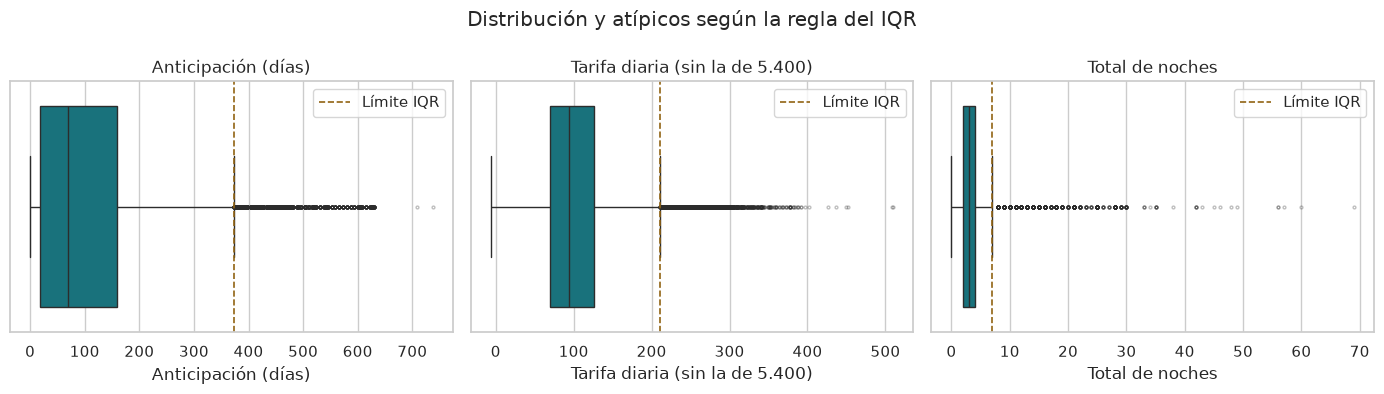

In [19]:
etiquetas = {
    "lead_time": "Anticipación (días)",
    "adr": "Tarifa diaria (sin la de 5.400)",
    "noches": "Total de noches",
}

fig, axes = plt.subplots(1, 3, figsize=(14, 4))
for ax, (nombre, serie) in zip(axes, variables_atipicos.items()):
    if nombre == "adr":
        serie = serie[serie <= TARIFA_MAXIMA_RAZONABLE]
    _, superior = limites_iqr(variables_atipicos[nombre])
    sns.boxplot(x=serie, ax=ax, color=COLOR_PRINCIPAL,
                flierprops={"markersize": 2, "alpha": 0.3})
    ax.axvline(superior, color=COLOR_RIESGO, linestyle="--", linewidth=1.2, label="Límite IQR")
    ax.set_title(etiquetas[nombre])
    ax.set_xlabel(etiquetas[nombre])
    ax.legend(loc="upper right")
fig.suptitle("Distribución y atípicos según la regla del IQR")
plt.tight_layout()
plt.show()

Para ver a qué reservas corresponden los atípicos, comparamos su perfil con el de todas las reservas.

In [20]:
def perfil(mascara):
    """Resume segmento, hotel, mes, repetidas y huéspedes de las reservas marcadas."""
    seleccion = reservas[mascara]
    return {
        "reservas": int(mascara.sum()),
        "% Groups": round((seleccion["market_segment"] == "Groups").mean() * 100, 1),
        "% Online TA": round((seleccion["market_segment"] == "Online TA").mean() * 100, 1),
        "% Resort Hotel": round((seleccion["hotel"] == "Resort Hotel").mean() * 100, 1),
        "% llegada en julio o agosto": round(seleccion["arrival_date_month"].isin(["July", "August"]).mean() * 100, 1),
        "% filas repetidas": round(duplicadas[mascara].mean() * 100, 1),
        "mediana de huéspedes": total_huespedes[mascara].median(),
    }


todas = pd.Series(True, index=reservas.index)
perfiles = {f"atípicos de {nombre}": perfil(mascara) for nombre, mascara in atipicos.items()}
perfiles["todas las reservas"] = perfil(todas)
pd.DataFrame.from_dict(perfiles, orient="index")

,reservas,% Groups,% Online TA,% Resort Hotel,% llegada en julio o agosto,% filas repetidas,mediana de huéspedes
atípicos de lead_time,3005,67.3,0.3,14.3,29.7,82.1,2.0
atípicos de adr,3793,2.6,70.9,66.0,73.5,4.5,3.0
atípicos de noches,5257,5.6,46.4,76.3,36.5,7.5,2.0
todas las reservas,119390,16.6,47.3,33.6,22.2,26.8,2.0


**¿Qué vemos?**

- **`lead_time`.** Desde 373 días de anticipación una reserva es atípica, y hay 3.005 (2,52 %), con un máximo de 737 días. No parecen errores: el 67,3 % son del segmento *Groups* y el 82,1 % son filas repetidas, o sea, bloqueos de habitaciones que las agencias hacen con más de un año de anticipación. Cancelan 66,7 %, casi el doble que el resto (36,3 %). Quitarlas sería botar justo un tipo de reserva que cancela mucho.
- **`adr`.** Por encima de 211,06 hay 3.793 tarifas atípicas (3,18 %). El 73,5 % llega en julio o agosto, el 66,0 % es del Resort Hotel y la mediana es de 3 huéspedes: son habitaciones grandes en temporada alta en la playa, que es normal que sean caras. Cancelan casi igual que el resto (38,7 % contra 37,0 %). La excepción es la tarifa de 5.400, que ya vimos que es un error. La tarifa negativa no sale como atípica porque el límite inferior es −15,77.
- **Noches.** Desde 8 noches una estancia es atípica: 5.257 reservas (4,40 %), con un máximo de 69 noches. El 76,3 % son del Resort Hotel, que es lo esperable para vacaciones de playa. Tampoco cambian la cancelación (35,7 % contra 37,1 %).
- En los tres casos el límite inferior queda negativo, así que la regla solo marca valores altos.

En general, los atípicos de estas tres variables son reservas reales con un comportamiento distinto, no errores, y tienen información útil. Lo que sí hacen es estirar mucho las distribuciones hacia la derecha, y eso afecta a los métodos que dependen de distancias o de la media, como K-Means o el escalado estándar.

### 2.6 Variables de alta cardinalidad

`country`, `agent` y `company` tienen muchas categorías. Para cada una contamos cuántas hay, qué porcentaje de las reservas (con dato) acumulan las más frecuentes y cuántas categorías tienen muy pocas reservas.

In [21]:
def resumen_cardinalidad(serie):
    """Cuántas categorías hay, cuánto acumulan las más frecuentes y cuántas son raras."""
    conteo = serie.value_counts()
    acumulado = conteo.cumsum() / conteo.sum() * 100
    resumen = {"categorias": len(conteo), "reservas_con_dato": conteo.sum()}
    for tope in TOPES_CATEGORIAS:
        resumen[f"top_{tope}_%"] = round(acumulado.iloc[tope - 1], 1)
    resumen["categorias_para_el_90_%"] = int((acumulado < 90).sum() + 1)
    resumen[f"con_menos_de_{MINIMO_RESERVAS_CATEGORIA}"] = int((conteo < MINIMO_RESERVAS_CATEGORIA).sum())
    resumen["con_una_sola_reserva"] = int((conteo == 1).sum())
    codigo = conteo.index[0]
    resumen["mas_frecuente"] = int(codigo) if isinstance(codigo, float) else codigo
    resumen["mas_frecuente_%"] = round(conteo.iloc[0] / conteo.sum() * 100, 1)
    return resumen


cardinalidad = pd.DataFrame.from_dict(
    {columna: resumen_cardinalidad(reservas[columna]) for columna in COLUMNAS_ALTA_CARDINALIDAD},
    orient="index",
)
cardinalidad

,categorias,reservas_con_dato,top_5_%,top_10_%,top_20_%,categorias_para_el_90_%,con_menos_de_100,con_una_sola_reserva,mas_frecuente,mas_frecuente_%
country,177,118902,73.2,84.8,94.2,14,139,30,PRT,40.9
agent,333,103050,58.5,69.2,78.3,52,249,50,9,31.0
company,352,6797,35.9,45.9,56.9,122,341,80,40,13.6


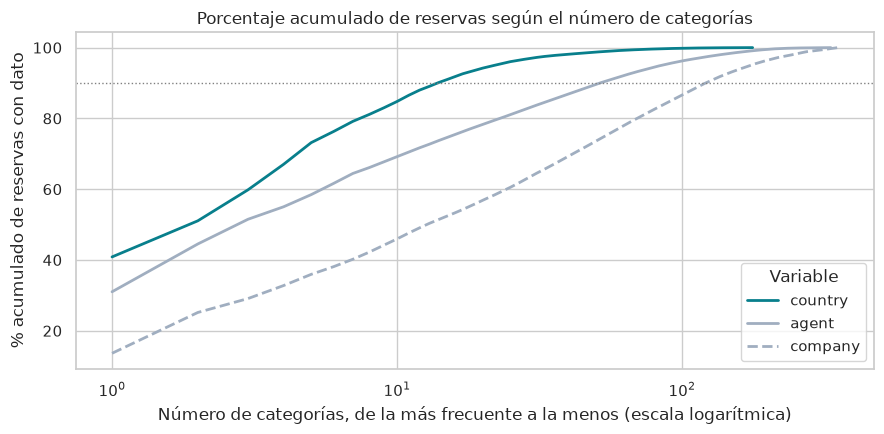

Si las tres entraran completas con one-hot serían 862 columnas nuevas


In [22]:
estilos = {
    "country": {"color": COLOR_PRINCIPAL, "linestyle": "-"},
    "agent": {"color": COLOR_SECUNDARIO, "linestyle": "-"},
    "company": {"color": COLOR_SECUNDARIO, "linestyle": "--"},
}

fig, ax = plt.subplots(figsize=(9, 4.5))
for columna in COLUMNAS_ALTA_CARDINALIDAD:
    conteo = reservas[columna].value_counts()
    acumulado = conteo.cumsum() / conteo.sum() * 100
    ax.plot(range(1, len(conteo) + 1), acumulado.values, label=columna, linewidth=2, **estilos[columna])
ax.axhline(90, color="gray", linestyle=":", linewidth=1)
ax.set_xscale("log")
ax.set_title("Porcentaje acumulado de reservas según el número de categorías")
ax.set_xlabel("Número de categorías, de la más frecuente a la menos (escala logarítmica)")
ax.set_ylabel("% acumulado de reservas con dato")
ax.legend(title="Variable")
plt.tight_layout()
plt.show()

print(f"Si las tres entraran completas con one-hot serían {cardinalidad['categorias'].sum()} columnas nuevas")

**¿Qué vemos?**

- **`country`** tiene 177 países, pero 14 ya acumulan el 90 % de las reservas y uno solo, Portugal (`PRT`), tiene el 40,9 %. 139 países tienen menos de 100 reservas y 30 tienen una sola.
- **`agent`** tiene 333 agencias. La agencia 9 sola tiene el 31,0 % de las reservas con agente, pero la cola es larga: hacen falta 52 agencias para llegar al 90 % y 249 tienen menos de 100 reservas.
- **`company`** es la más dispersa: 352 empresas repartidas en solo 6.797 reservas. La más frecuente no llega al 14 %, se necesitan 122 empresas para el 90 % y 341 tienen menos de 100 reservas.
- Si las tres entraran completas con *one-hot* tendríamos 862 columnas nuevas, la mayoría casi vacías. Con una categoría que tiene una o dos reservas, el modelo no puede aprender nada que generalice; lo que aprende es ruido. Además, una categoría que solo aparece en prueba no tendría columna.

En la gráfica se ve la diferencia: la línea de `country` sube muy rápido (pocas categorías explican casi todo), la de `agent` sube a un ritmo medio y la de `company` va subiendo despacio porque está muy repartida.

Lo que no podemos decir todavía es si estas variables sirven para predecir. Eso depende de la sección 3, sobre todo para `country`, que puede tener fuga.

### 2.7 Cierre de la sección: problemas encontrados y tratamiento propuesto

| Problema | Qué encontramos | Tratamiento que proponemos para el notebook 02 |
|---|---|---|
| Faltantes en `company` | 112.593 (94,31 %). Vacío = la reserva no es de empresa | No usar el código. Crear el indicador `tiene_empresa` (1 si tiene dato, 0 si no) |
| Faltantes en `agent` | 16.340 (13,69 %), casi todos en los canales *Direct* y *Corporate* | Llenarlos con la categoría "Sin agente" |
| Faltantes en `country` | 488 (0,41 %), cancelan 13,7 % | Llenarlos con "Desconocido", si la sección 3 decide que `country` entra |
| Faltantes en `children` | 4 reservas | Llenarlos con 0 y volver la columna entera |
| `Undefined` en `meal` | 1.169, equivale a `SC` (sin plan) | Unir `Undefined` con `SC` |
| `Undefined` en `market_segment` y `distribution_channel` | 2 y 5 reservas | Dejarlas; la codificación las agrupa con las categorías raras |
| `agent` y `company` leídas como números | Son códigos, no cantidades | Tratar `agent` como categórica |
| `arrival_date_month` como texto | Mes en inglés | Pasarla a número de mes |
| Duplicados | 31.994 filas (26,8 %); cancelan 63,1 %; sobre todo *Groups* y *Non Refund* | Dejar una sola fila por combinación **antes** de partir en entrenamiento y prueba, para que una misma fila no quede en los dos lados. Tener presente que la cancelación baja a 27,5 % y reportarlo |
| Tarifas imposibles | Una de −6,38 y una de 5.400 | Quitar las dos filas |
| Cero huéspedes | 180 reservas | Quitarlas |
| Cero noches | 715 reservas, todas con tarifa 0 | Quitarlas, porque no son estancias |
| Nueve o más niños o bebés | 3 reservas | Quitarlas |
| Niños sin adulto | 223 reservas | Dejarlas; son raras pero posibles |
| Atípicos de `lead_time`, `adr` y noches | 2,52 %, 3,18 % y 4,40 % de las reservas; son reservas reales | No quitarlos. Tenerlos en cuenta al escalar y en K-Means (por ejemplo, con una transformación logarítmica) |
| Alta cardinalidad de `country` y `agent` | 177 y 333 categorías; muchas con menos de 100 reservas | *One-hot* que agrupe las categorías poco frecuentes en "otras", ajustado solo con entrenamiento |

Todo lo que dependa de los datos, como qué categorías son frecuentes, se tiene que calcular solo con entrenamiento. Por eso lo dejamos como propuesta y no lo aplicamos aquí. Las filas que se quitan por reglas fijas (tarifas imposibles, cero huéspedes) sí se pueden quitar antes de partir, porque la regla no aprende nada de los datos.

Lo que sigue es mirar las cancelaciones: cómo se distribuyen, con qué variables se relacionan y cuáles hay que dejar por fuera por fuga de información. Eso es la sección 3.